In [15]:
import pandas as pd
import numpy as np
import re

In [6]:
df=pd.read_excel("Accesco QC SKU Master Inventory.xlsx")

In [7]:
df.head()

,SKU ID,Product Name,Brand,Category,Sub-Category,Product Type,Pack Size,Unit,MRP (Rs.),Selling Price (Rs.),Margin %,Avg Daily Demand (units),Reorder Level,ABC Class,Velocity,Temp Zone,Shelf Life,Purchase Type,Seasonal
0,ACS-DB&-1001,Amul Gold Full Cream Milk 180 ml,Amul Gold,"Dairy, Bread & Eggs",Milk,Full Cream Milk,180 ml,ml,25,21,11,75,137,B,Fast,Chilled,2 days,Planned,No
1,ACS-DB&-1002,Amul Gold Full Cream Milk 500 ml,Amul Gold,"Dairy, Bread & Eggs",Milk,Full Cream Milk,500 ml,ml,68,63,9,109,260,A,Fast,Chilled,2 days,Planned,No
2,ACS-DB&-1003,Amul Gold Full Cream Milk 1 L,Amul Gold,"Dairy, Bread & Eggs",Milk,Full Cream Milk,1 L,L,82,68,16,69,165,A,Fast,Chilled,2 days,Planned,No
3,ACS-DB&-1004,Mother Dairy Full Cream Milk 180 ml,Mother Dairy,"Dairy, Bread & Eggs",Milk,Full Cream Milk,180 ml,ml,28,26,14,109,199,B,Fast,Chilled,2 days,Planned,No
4,ACS-DB&-1005,Mother Dairy Full Cream Milk 500 ml,Mother Dairy,"Dairy, Bread & Eggs",Milk,Full Cream Milk,500 ml,ml,68,64,10,40,101,A,Fast,Chilled,2 days,Planned,No


In [8]:
df.isnull().sum()

SKU ID                       0
Product Name                 0
Brand                        0
Category                     0
Sub-Category                 0
Product Type                 0
Pack Size                    0
Unit                         0
MRP (Rs.)                    0
Selling Price (Rs.)          0
Margin %                     0
Avg Daily Demand (units)     0
Reorder Level                0
ABC Class                    0
Velocity                     0
Temp Zone                    0
Shelf Life                  11
Purchase Type                0
Seasonal                     0
dtype: int64

In [12]:
df[df['Shelf Life'].isnull()].to_csv("missing_Shelf_life.csv")

In [13]:
df.duplicated().sum()

np.int64(0)

In [16]:
def parse_shelf_life_to_days(val):
    if pd.isnull(val):
        return np.nan # Non-perishable / indefinite
    
    val = str(val).strip().lower()
    
    # Extract days
    m_day = re.search(r'(\d+)\s*day', val)
    if m_day:
        return int(m_day.group(1))
    
    # Extract months (approx 30 days)
    m_month = re.search(r'(\d+)\s*month', val)
    if m_month:
        return int(m_month.group(1)) * 30
    
    # Extract years (approx 365 days)
    m_year = re.search(r'(\d+)\s*year', val)
    if m_year:
        return int(m_year.group(1)) * 365
        
    return np.nan

In [17]:
df['Shelf_Life_Days'] = df['Shelf Life'].apply(parse_shelf_life_to_days)

In [18]:
# 2. Perishability Tiering
# Categorize based on Accesco's operational shelf-life brackets
def categorize_perishability(days):
    if pd.isna(days):
        return 'Non-Perishable'
    elif days <= 7:
        return 'Ultra-Perishable / Daily FEFO'
    elif days <= 30:
        return 'Short Shelf Life'
    elif days <= 180:
        return 'Medium Shelf Life'
    else:
        return 'Stable / Non-Perishable'

df['Perishability_Tier'] = df['Shelf_Life_Days'].apply(categorize_perishability)

In [19]:
# 3. Financial Metrics (Revenue, Gross Profit & Working Capital)
# Calculate daily GMV and Profit using Average Daily Demand and Margin %
df['Daily_GMV'] = df['Avg Daily Demand (units)'] * df['Selling Price (Rs.)']
df['Daily_Gross_Profit'] = df['Daily_GMV'] * (df['Margin %'] / 100.0)

In [20]:
df['Discount_Pct'] = ((df['MRP (Rs.)'] - df['Selling Price (Rs.)']) / df['MRP (Rs.)']) * 100

In [21]:
# 4. Inventory Constraints & Reorder Benchmarks
# Compute the current deterministic stock cover in days based on Reorder Level
df['Target_ROL_Days'] = df['Reorder Level'] / df['Avg Daily Demand (units)']

In [22]:
df.head()

,SKU ID,Product Name,Brand,Category,Sub-Category,Product Type,Pack Size,Unit,MRP (Rs.),Selling Price (Rs.),...,Temp Zone,Shelf Life,Purchase Type,Seasonal,Shelf_Life_Days,Perishability_Tier,Daily_GMV,Daily_Gross_Profit,Discount_Pct,Target_ROL_Days
0,ACS-DB&-1001,Amul Gold Full Cream Milk 180 ml,Amul Gold,"Dairy, Bread & Eggs",Milk,Full Cream Milk,180 ml,ml,25,21,...,Chilled,2 days,Planned,No,2.0,Ultra-Perishable / Daily FEFO,1575,173.25,16.000000,1.826667
1,ACS-DB&-1002,Amul Gold Full Cream Milk 500 ml,Amul Gold,"Dairy, Bread & Eggs",Milk,Full Cream Milk,500 ml,ml,68,63,...,Chilled,2 days,Planned,No,2.0,Ultra-Perishable / Daily FEFO,6867,618.03,7.352941,2.385321
2,ACS-DB&-1003,Amul Gold Full Cream Milk 1 L,Amul Gold,"Dairy, Bread & Eggs",Milk,Full Cream Milk,1 L,L,82,68,...,Chilled,2 days,Planned,No,2.0,Ultra-Perishable / Daily FEFO,4692,750.72,17.073171,2.391304
3,ACS-DB&-1004,Mother Dairy Full Cream Milk 180 ml,Mother Dairy,"Dairy, Bread & Eggs",Milk,Full Cream Milk,180 ml,ml,28,26,...,Chilled,2 days,Planned,No,2.0,Ultra-Perishable / Daily FEFO,2834,396.76,7.142857,1.825688
4,ACS-DB&-1005,Mother Dairy Full Cream Milk 500 ml,Mother Dairy,"Dairy, Bread & Eggs",Milk,Full Cream Milk,500 ml,ml,68,64,...,Chilled,2 days,Planned,No,2.0,Ultra-Perishable / Daily FEFO,2560,256.00,5.882353,2.525000


In [23]:
df.to_csv("After_FE_Accesco_QC_SKU_Master_Inventory.csv")

In [26]:
df[df['Shelf Life'].isnull()]['SKU ID'].values

<ArrowStringArray>
['ACS-E&A-3701', 'ACS-E&A-3702', 'ACS-E&A-3703', 'ACS-E&A-3704',
 'ACS-E&A-3705', 'ACS-E&A-3706', 'ACS-E&A-3707', 'ACS-E&A-3708',
 'ACS-E&A-3709', 'ACS-E&A-3710', 'ACS-E&A-3711']
Length: 11, dtype: str

In [32]:
df[df['Shelf Life'].isnull()][['SKU ID','Product Name']]

,SKU ID,Product Name
2700,ACS-E&A-3701,boAt Charging Cable 1 pc
2701,ACS-E&A-3702,Mi Charging Cable 1 pc
2702,ACS-E&A-3703,Portronics Charging Cable 1 pc
2703,ACS-E&A-3704,Ambrane Charging Cable 1 pc
2704,ACS-E&A-3705,boAt Earphones 1 pc
2705,ACS-E&A-3706,Realme Earphones 1 pc
2706,ACS-E&A-3707,JBL Earphones 1 pc
2707,ACS-E&A-3708,Mi Earphones 1 pc
2708,ACS-E&A-3709,Mi Power Bank 1 pc
2709,ACS-E&A-3710,boAt Power Bank 1 pc


In [34]:
df[df['Shelf Life'].isnull()][['SKU ID','Product Name']].to_csv("SKU ID and product name missing.csv")

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\laksh\AppData\Local\Temp\ipykernel_10132\3461876404.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Perishability_Tier', order=df['Perishability_Tier'].value_counts().index, ax=axes[0,0], palette='viridis')
C:\Users\laksh\AppData\Local\Temp\ipykernel_10132\3461876404.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=gmv_by_abc, x='ABC Class', y='Daily_GMV', ax=axes[1,0], palette='magma', order=['A', 'B', 'C'])
C:\Users\laksh\AppData\Local\Temp\ipykernel_10132\3461876404.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

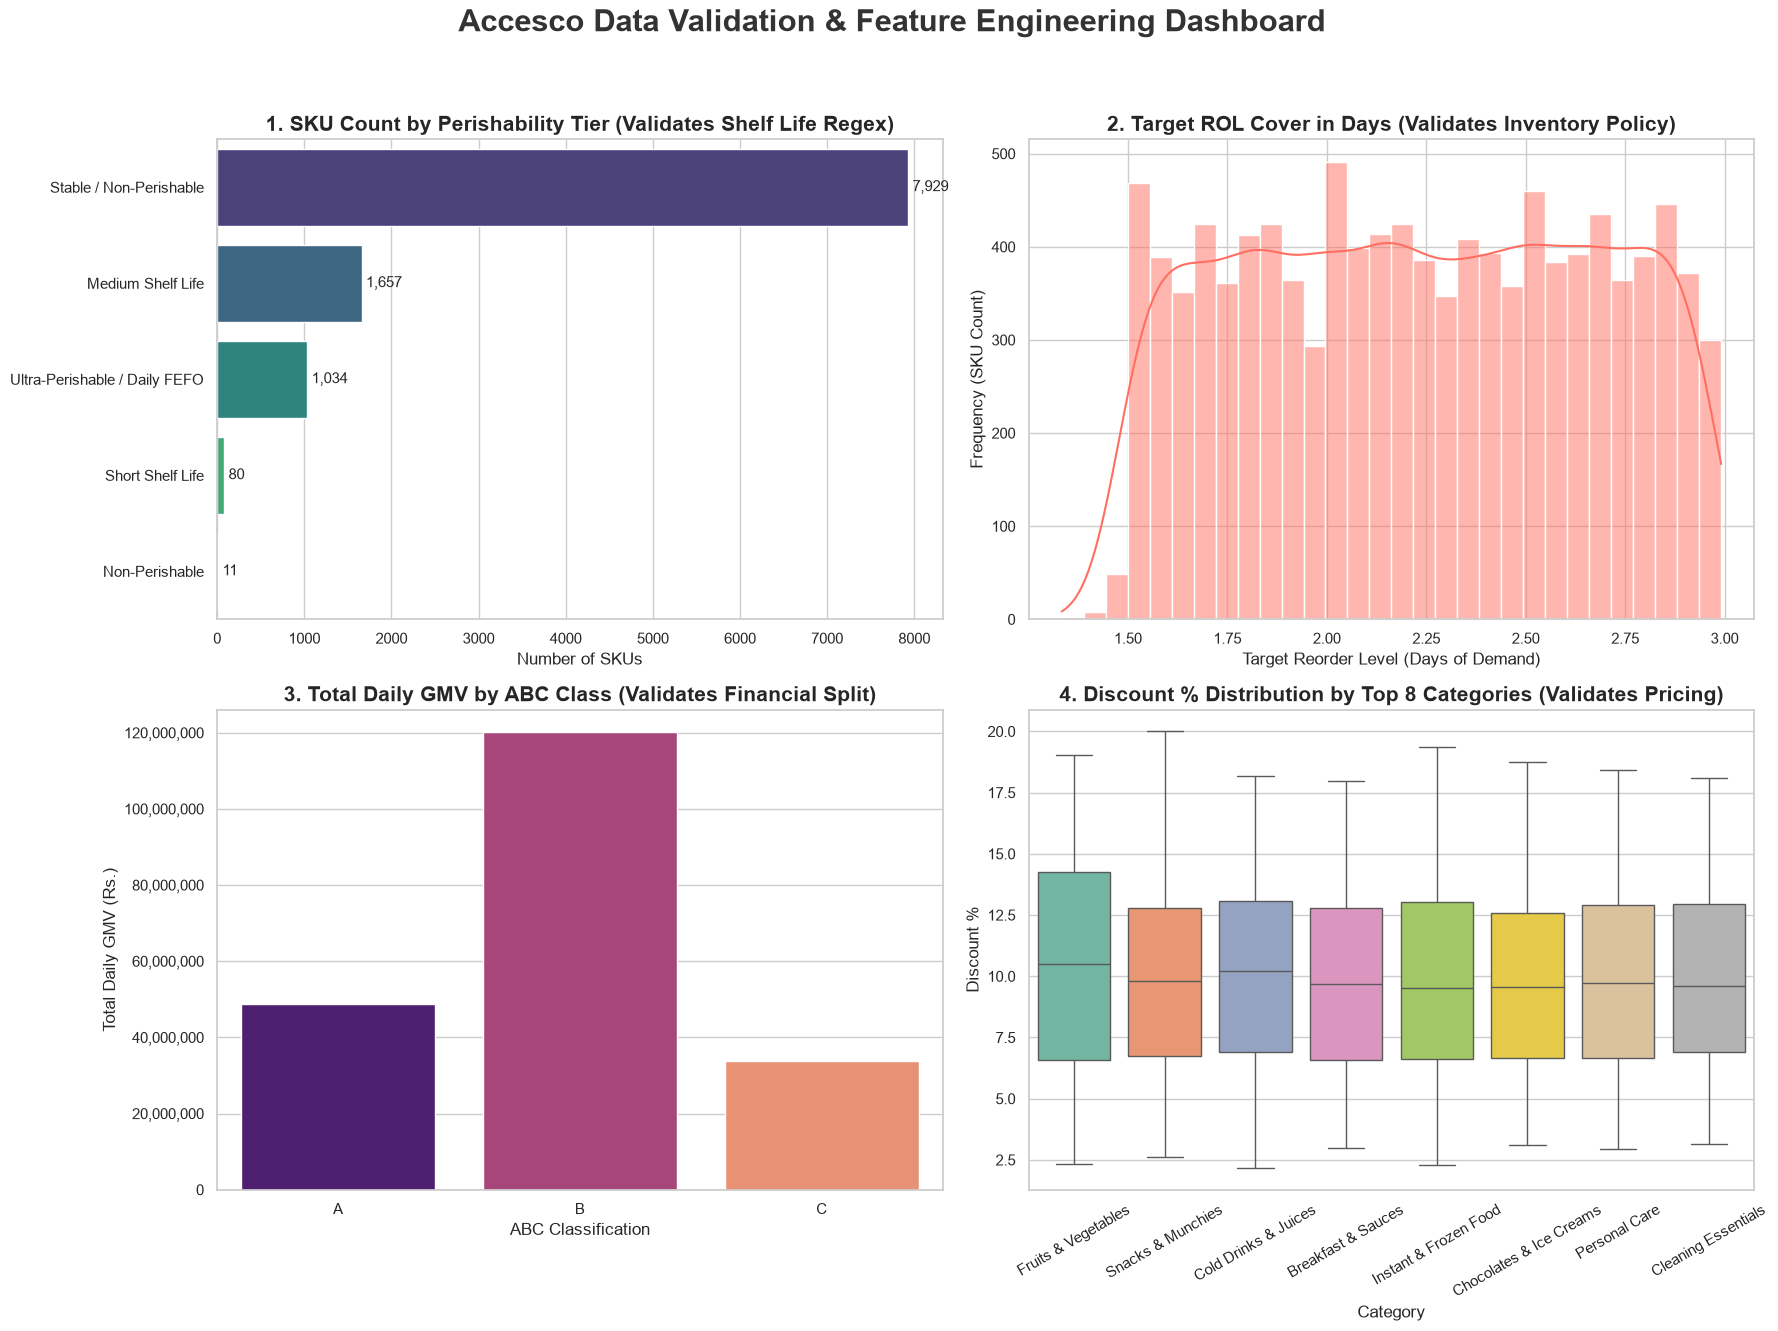

In [37]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Accesco Data Validation & Feature Engineering Dashboard', fontsize=22, fontweight='bold', color='#333333')

sns.countplot(data=df, y='Perishability_Tier', order=df['Perishability_Tier'].value_counts().index, ax=axes[0,0], palette='viridis')
axes[0,0].set_title('1. SKU Count by Perishability Tier (Validates Shelf Life Regex)', fontsize=15, fontweight='bold')
axes[0,0].set_xlabel('Number of SKUs', fontsize=12)
axes[0,0].set_ylabel('')
for p in axes[0,0].patches:
    width = p.get_width()
    axes[0,0].annotate(f'{int(width):,}', (width + 50, p.get_y() + p.get_height() / 2), ha='left', va='center', fontsize=11)

# Top-Right: Target ROL Days Distribution
sns.histplot(data=df, x='Target_ROL_Days', bins=30, kde=True, ax=axes[0,1], color='#FF6F61')
axes[0,1].set_title('2. Target ROL Cover in Days (Validates Inventory Policy)', fontsize=15, fontweight='bold')
axes[0,1].set_xlabel('Target Reorder Level (Days of Demand)', fontsize=12)
axes[0,1].set_ylabel('Frequency (SKU Count)', fontsize=12)

# Bottom-Left: Daily GMV by ABC Class
gmv_by_abc = df.groupby('ABC Class')['Daily_GMV'].sum().reset_index()
sns.barplot(data=gmv_by_abc, x='ABC Class', y='Daily_GMV', ax=axes[1,0], palette='magma', order=['A', 'B', 'C'])
axes[1,0].set_title('3. Total Daily GMV by ABC Class (Validates Financial Split)', fontsize=15, fontweight='bold')
axes[1,0].set_xlabel('ABC Classification', fontsize=12)
axes[1,0].set_ylabel('Total Daily GMV (Rs.)', fontsize=12)
axes[1,0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Bottom-Right: Discount % Distribution (Top 8 Categories)
top_cats = df['Category'].value_counts().head(8).index
sns.boxplot(data=df[df['Category'].isin(top_cats)], x='Category', y='Discount_Pct', ax=axes[1,1], palette='Set2')
axes[1,1].set_title('4. Discount % Distribution by Top 8 Categories (Validates Pricing)', fontsize=15, fontweight='bold')
axes[1,1].set_xlabel('Category', fontsize=12)
axes[1,1].set_ylabel('Discount %', fontsize=12)
axes[1,1].tick_params(axis='x', rotation=30)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()